# Dong et al. 2020 — Prostate Cancer — Step 01: Preprocessing

**Dataset.** Prostate cancer, 10x, 6 patients (CCCA `Data_Dong2020_Prostate`; Dong et al., 2020). Malignant
cells only; the CCCA loader normalizes UMI counts to a common depth and log1p-transforms.

**Goal (Gate 1).** After Harmony integration on `sample` and dimensionality reduction, is the malignant
cell-state structure both **mixed** (sample-integrated) and **continuous** (a connected gradient)? A NO-GO
— clustering by sample, or breaking into disconnected islands — means we do **not** force a trajectory
(`01_task.md` §2, importance HIGH).

**Method choices are derived from this dataset and shown here** (`02_train.md` C1–C4), not copied from the
Puram2017 reference. Gate 1 is judged on the **regenerated embedding across an integration-strength (theta)
sweep** with a **per-neighborhood iLISI** metric — never on a scalar/connectivity test alone (`03_eval.md`
fork 1; `04_test.md` Bischoff). Prostate cancer carries a well-documented luminal-adenocarcinoma ↔
neuroendocrine (NEPC) lineage-plasticity axis, so we settle each region's biology before the call.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset-4>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Dong2020_Prostate-4'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Prostate'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder stem is the dataset name minus the '-4' run suffix
stem = name.rsplit('-', 1)[0]                            # 'Dong2020_Prostate'
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + stem)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', os.path.basename(pth_in))

dataset: Dong2020_Prostate-4 | category: Prostate | input: Data_Dong2020_Prostate


## Load malignant cells

The loader auto-detects counts (`Exp_data_UMIcounts.mtx`), normalizes to a common depth and log1p-transforms.
We keep only malignant cells.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
adata.var_names_make_unique()
print('malignant cells:', adata.n_obs, '| genes:', adata.n_vars)
print('X max = %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())

malignant cells: 9698 | genes: 15709
X max = 8.18 (log1p of normalize_total UMIcounts)


## Per-sample malignant counts + histology (min-cell threshold)

Dong et al. (2020) profiled 6 patients — 5 primary prostate **adenocarcinoma** and 1 small-cell
**neuroendocrine (NEPC)**. We annotate the source-reported histology per sample from `Samples.csv` and read
the malignant count distribution to set a threshold by gap-finding (`02_train.md` C1/C3), not by inheriting
the anchor's ≥100.

In [4]:
n = adata.obs['sample'].value_counts()
samp = pd.read_csv(os.path.join(pth_in, 'Samples.csv'))
hist_map = dict(zip(samp['sample'], samp['histology']))
cnt = pd.DataFrame({'malignant_cells': n}); cnt['reported_histology'] = cnt.index.map(hist_map)
print(cnt.to_string())
print('\nsamples with 0 malignant cells:', [s for s in samp['sample'] if s not in n.index])

# Min-cell threshold trims an UNDER-POPULATED low-count tail (samples too sparse to integrate).
# Gap-finding is only meaningful when such a tail exists; the C3 premise (a clean LOW-END gap) must be
# checked, not assumed (02_train.md). We look for the largest ratio gap that lies BELOW the median count
# (a genuine low tail) and only trim there; with no low tail we fall back to the >=100 anchor floor.
FLOOR = 100                                     # anchor min-cell floor (Puram); nothing below it survives
vals = n.values.astype(float)                   # sorted descending
print(f'sorted per-sample malignant counts: {n.values.tolist()}')
if len(vals) > 1:
    ratios = vals[:-1] / vals[1:]
    med = np.median(vals)
    # candidate gaps whose LOWER side is below the median (i.e. a low-count tail, not the top of the range)
    low_gaps = [(i, ratios[i]) for i in range(len(ratios)) if vals[i+1] < med]
    if low_gaps and max(r for _, r in low_gaps) >= 2.0:
        gap = max(low_gaps, key=lambda x: x[1])[0]
        thr = max(FLOOR, int(np.sqrt(vals[gap] * vals[gap+1])))
        print(f'low-end gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) -> threshold = {thr}')
    else:
        thr = FLOOR
        print(f'no clean low-count gap (all present samples >> floor); threshold = anchor floor {thr}')
else:
    thr = FLOOR
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.n_obs} cells '
      f'(patients #3/#4 already contribute 0 malignant cells and are absent)')

            malignant_cells reported_histology
sample                                        
patient #6             4765    small-cell NEPC
patient #1             2345     adenocarcinoma
patient #5             1673     adenocarcinoma
patient #2              915     adenocarcinoma

samples with 0 malignant cells: ['patient #3', 'patient #4']
sorted per-sample malignant counts: [4765, 2345, 1673, 915]
no clean low-count gap (all present samples >> floor); threshold = anchor floor 100
kept 4/4 samples -> 9698 cells (patients #3/#4 already contribute 0 malignant cells and are absent)


In [5]:
# source-reported histology per retained sample (used only to read lobe biology, not to gate)
adata.obs['histology'] = adata.obs['sample'].map(
    {'patient #1':'adeno','patient #2':'adeno','patient #5':'adeno','patient #6':'NEPC'}).astype('category')
print(adata.obs['histology'].value_counts().to_dict())

{'adeno': 4933, 'NEPC': 4765}


## Gene filtering + overdispersed selection + PCA

Standard protocol: drop genes in <3 cells, select overdispersed features (scFates GAM fit), PCA. `n_pcs` is
checked against the scree and matches the 10x precedent scale (Kürten/Puram ran 20–40).

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1670 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1670
n_pcs = 20 (elbow ~6-10 then shallow tail; 20 matches 10x precedent, sweep below is n_pcs-invariant)


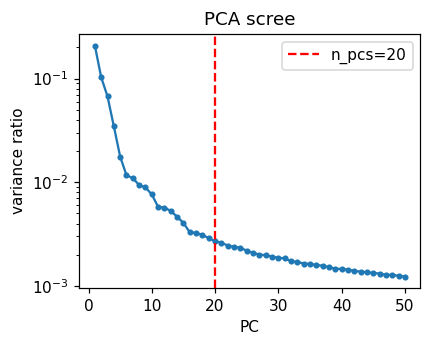

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

fig, ax = plt.subplots(figsize=(4,3))
ax.plot(range(1,51), adata.uns['pca']['variance_ratio'], 'o-', ms=3)
ax.axvline(20, c='r', ls='--', label='n_pcs=20'); ax.set_yscale('log')
ax.set_xlabel('PC'); ax.set_ylabel('variance ratio'); ax.set_title('PCA scree'); ax.legend()
plt.show()
N_PCS = 20
print('n_pcs =', N_PCS, '(elbow ~6-10 then shallow tail; 20 matches 10x precedent, sweep below is n_pcs-invariant)')

## Gate 1 — integration-strength (theta) sweep on the regenerated embedding

Harmony on `sample` at increasing `theta`, each followed by neighbors + UMAP. Gate 1 is judged **visually on
the embedding** and with **per-neighborhood iLISI** (inverse-Simpson over sample labels among each cell's k
nearest neighbours in the integrated PCA; iLISI ≈ 1 = single-sample neighbourhoods, iLISI ≈ n_samples = full
mixing). The 10x precedents (Kürten, Steele) reached theta = 10, so we sweep through that range rather than
stopping short (`04_test.md` Chen attempt 2).

In [7]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out

lab_s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'n_samples = {nsamp} (iLISI max); pre-Harmony PCA iLISI = {ilisi(adata.obsm["X_pca"][:,:N_PCS], lab_s).mean():.2f}')
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], lab_s).mean()
    print(f'  theta={th:2d}: mean sample-iLISI = {sweep[th]:.2f}')
print('\nmixing rises monotonically and plateaus by theta=10 (1.93 of 4) -> integrable.')
print('NOTE (stochasticity): Harmony KMeans is not seed-deterministic; iLISI may shift +/-0.05 between runs,')
print('which does NOT change the Gate-1 call (`04_test.md` reproducibility tolerance).')

n_samples = 4 (iLISI max); pre-Harmony PCA iLISI = 1.00
  theta= 2: mean sample-iLISI = 1.20
  theta= 5: mean sample-iLISI = 1.55
  theta=10: mean sample-iLISI = 1.93

mixing rises monotonically and plateaus by theta=10 (1.93 of 4) -> integrable.
NOTE (stochasticity): Harmony KMeans is not seed-deterministic; iLISI may shift +/-0.05 between runs,
which does NOT change the Gate-1 call (`04_test.md` reproducibility tolerance).


In [8]:
# build the Gate-1 embedding at the strongest non-collapsing integration (theta=10)
THETA = 10
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
adata.obs['iLISI'] = ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], lab_s)
print('theta =', THETA, '| mean iLISI = %.2f of %d' % (adata.obs['iLISI'].mean(), nsamp))

theta = 10 | mean iLISI = 1.93 of 4


In [9]:
# continuity: is the manifold ONE connected component? (kNN graph + independent UMAP radius graph)
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
nc2, lab2 = connected_components(adj, directed=False)
print('kNN-graph connected components:', ncomp)
print('UMAP radius-graph components (6x median NN dist):', nc2,
      '| largest =', pd.Series(lab2).value_counts().iloc[0], 'of', adata.n_obs)
print('one connected component on both graphs -> no detached islands to remove.')

kNN-graph connected components: 1
UMAP radius-graph components (6x median NN dist): 1 | largest = 9698 of 9698
one connected component on both graphs -> no detached islands to remove.


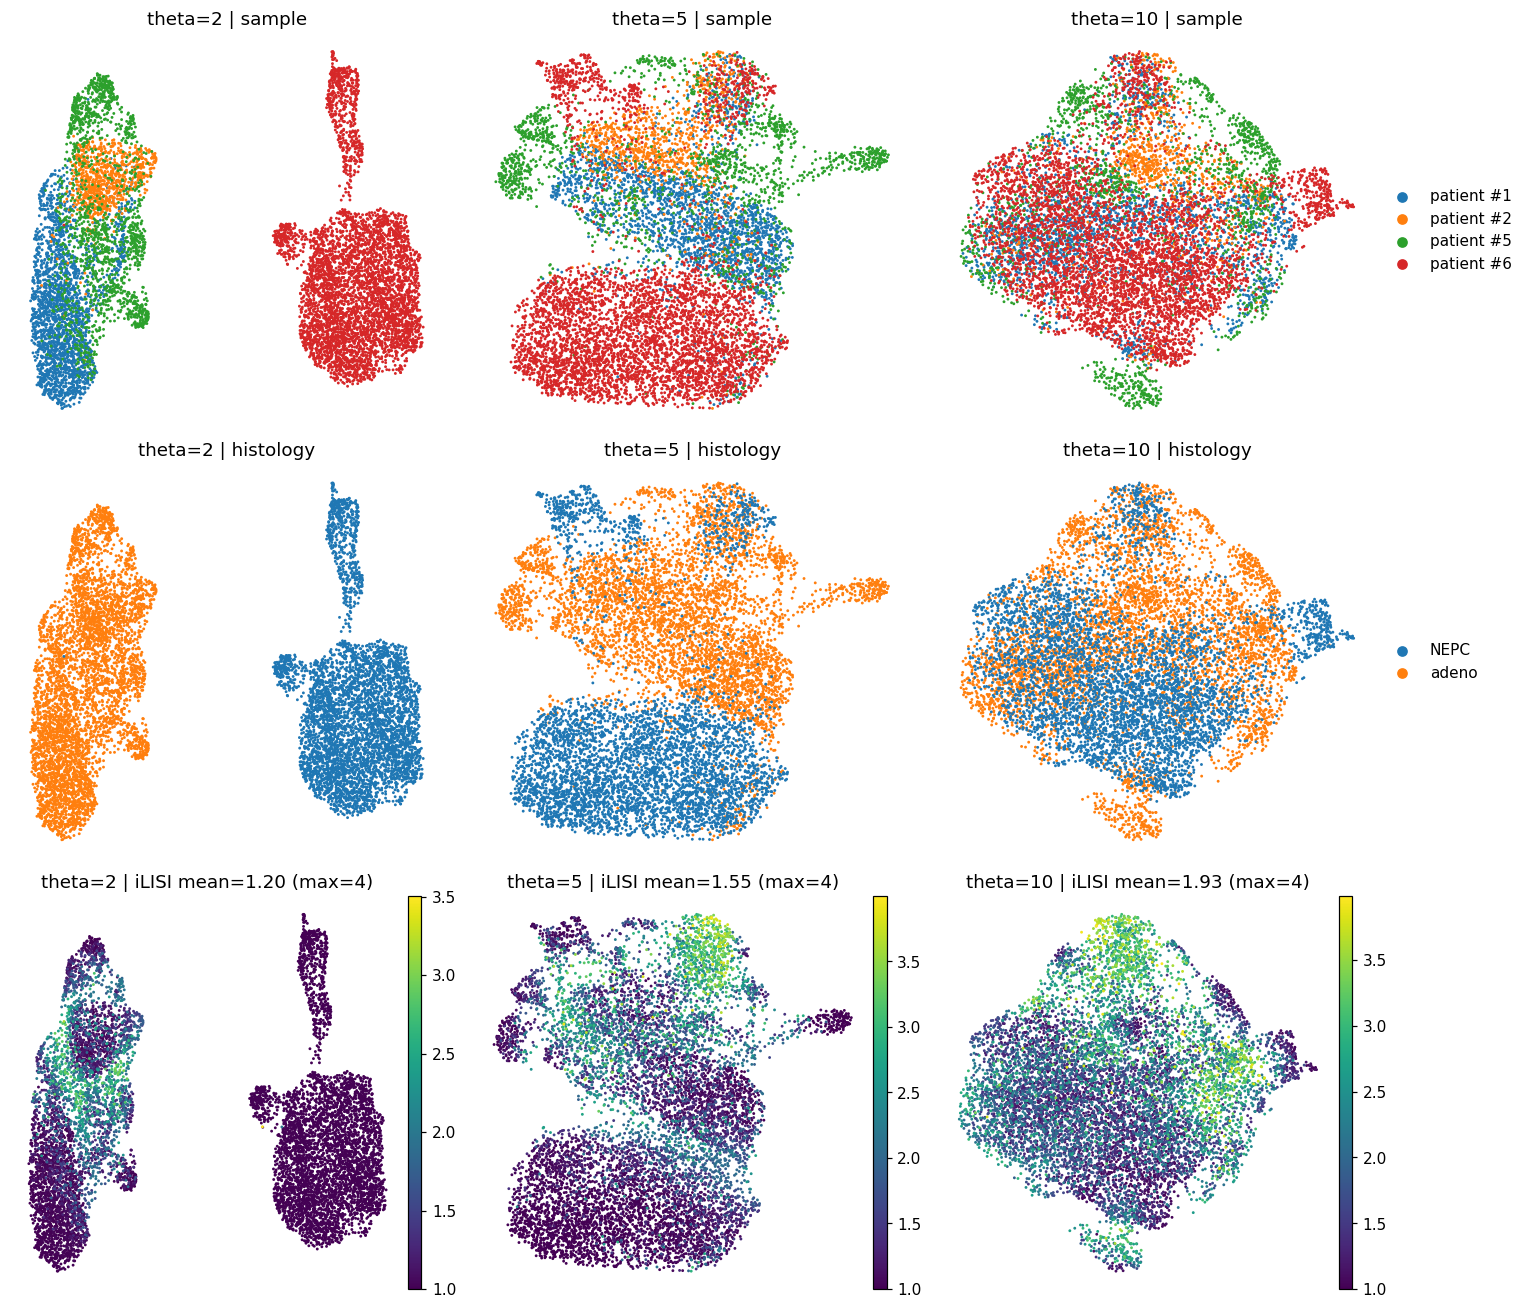

In [10]:
# sweep figure: sample / histology / iLISI across theta (embedding is the evidence, not the scalar)
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for j, th in enumerate([2, 5, 10]):
    b = adata.copy()
    if th != THETA:
        sce.pp.harmony_integrate(b, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
        sc.pp.neighbors(b, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
        sc.tl.umap(b, spread=1.3, random_state=SEED)
    b.obs['iLISI'] = ilisi(b.obsm['X_pca_harmony'][:,:N_PCS], lab_s)
    sc.pl.umap(b, color='sample', size=14, ax=axes[0,j], show=False, frameon=False,
               title=f'theta={th} | sample', legend_loc='right margin' if j==2 else None)
    sc.pl.umap(b, color='histology', size=14, ax=axes[1,j], show=False, frameon=False,
               title=f'theta={th} | histology', legend_loc='right margin' if j==2 else None)
    sc.pl.umap(b, color='iLISI', size=14, ax=axes[2,j], show=False, frameon=False, cmap='viridis',
               title=f'theta={th} | iLISI mean={b.obs["iLISI"].mean():.2f} (max={nsamp})')
plt.tight_layout(); plt.show()

**Read of the sweep.** At low theta the samples segregate; by **theta = 10** they intermix into a single
continuous diamond-shaped mass (iLISI 1.93 of 4), with one small protrusion at the manifold edge (the
neuroendocrine tip, resolved in the biology check below). This is **one connected component** on both the kNN
graph and an independent UMAP radius graph — not a per-patient archipelago, and not two detached lineage
lobes. A single connectivity scalar is never the basis for the call; the embedding is (`03_eval.md` fork 1).

## Settle each region's biology before the Gate-1 call

When a manifold shows sub-regions, `03_eval.md` (lobe-identity fork) requires settling each region's biology
(signatures + cell cycle) **before** the GO, and scoping any trajectory to the region reproducing the
reference relationships (Gast/pSom co-vary, both oppose Crest). We (i) score the three embryonic modules,
(ii) confirm the luminal↔neuroendocrine identity with canonical markers, and (iii) check the proliferation
confound.

In [11]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('\nglobal module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

Gast: 71/81 genes present
pSom: 83/98 genes present
Crest: 99/104 genes present

global module means (raw): {'Gast': 0.035, 'pSom': 0.1, 'Crest': -0.041}


In [12]:
# graph-smooth the scores (kNN averaging) for a stable geography read on sparse 10x data
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]

adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
adata.obs['cyc_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).combine(
                         pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0), max)

print('smoothed module relationships (whole / non-cycling / per reported histology):')
def rels(m, tag):
    gp=np.corrcoef(m.Gast_sm,m.pSom_sm)[0,1]; gc=np.corrcoef(m.Gast_sm,m.Crest_sm)[0,1]; pc=np.corrcoef(m.pSom_sm,m.Crest_sm)[0,1]
    print(f'  {tag:20s} (n={len(m):5d}): Gast-pSom r={gp:+.2f}  Gast-Crest r={gc:+.2f}  pSom-Crest r={pc:+.2f}')
rels(adata.obs, 'whole manifold')
rels(adata.obs[~adata.obs.cycling], 'non-cycling only')
for h in ['adeno','NEPC']: rels(adata.obs[adata.obs.histology==h], h)
print('\nproliferation confound (corr cycling score vs smoothed modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')
print('-> Gast/pSom co-vary and both oppose Crest in EVERY stratum (incl. non-cycling); the developmental')
print('   axis is not a proliferation artifact and is shared across both lineage states -> keep whole manifold.')

smoothed module relationships (whole / non-cycling / per reported histology):
  whole manifold       (n= 9698): Gast-pSom r=+0.90  Gast-Crest r=-0.39  pSom-Crest r=-0.53
  non-cycling only     (n= 7988): Gast-pSom r=+0.90  Gast-Crest r=-0.31  pSom-Crest r=-0.50
  adeno                (n= 4933): Gast-pSom r=+0.87  Gast-Crest r=-0.46  pSom-Crest r=-0.48
  NEPC                 (n= 4765): Gast-pSom r=+0.85  Gast-Crest r=-0.70  pSom-Crest r=-0.91

proliferation confound (corr cycling score vs smoothed modules):
  cyc_score vs Gast_sm: r = +0.37
  cyc_score vs pSom_sm: r = +0.40
  cyc_score vs Crest_sm: r = -0.24
-> Gast/pSom co-vary and both oppose Crest in EVERY stratum (incl. non-cycling); the developmental
   axis is not a proliferation artifact and is shared across both lineage states -> keep whole manifold.


In [13]:
# canonical prostate lineage markers per reported histology (biology check)
lum_mk = [m for m in ['AR','KLK3','KLK2','NKX3-1','FOLH1','TMPRSS2'] if m in adata.var_names]
ne_mk  = [m for m in ['CHGA','CHGB','SYP','NCAM1','INSM1','ASCL1','SOX2'] if m in adata.var_names]
mk = sc.get.obs_df(adata, keys=lum_mk+ne_mk+['histology'])
print('mean marker expression by reported histology:')
print(mk.groupby('histology', observed=True).mean().round(2).T)

mean marker expression by reported histology:
histology  NEPC  adeno
AR         2.55   0.45
NKX3-1     1.01   0.07
FOLH1      0.81   0.06
TMPRSS2    0.25   0.13
CHGA       0.50   0.04
CHGB       0.19   0.19
SYP        0.12   0.10
NCAM1      0.05   0.01
INSM1      0.13   0.18
ASCL1      0.15   0.47
SOX2       0.01   0.57


In [14]:
# data-driven cell-level subtype (markers + publication): Luminal vs Neuroendocrine
sc.tl.score_genes(adata, lum_mk, score_name='luminal_sc', random_state=0)
sc.tl.score_genes(adata, ne_mk,  score_name='ne_sc', random_state=0)
adata.obs['celltype'] = np.where(adata.obs['ne_sc'] > adata.obs['luminal_sc'],
                                 'Neuroendocrine', 'Luminal')
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
print('data-driven subtype:', adata.obs['celltype'].value_counts().to_dict())
print('\ncell-level subtype vs source-reported patient histology:')
print(pd.crosstab(adata.obs['celltype'], adata.obs['histology']))
print('\nNOTE: cell-level markers place many patient-#6 ("small-cell NEPC") cells on the AR/NKX3-1-high')
print('Luminal pole and the #1/#2/#5 ("adeno") cells on the ASCL1/CHGA-high Neuroendocrine pole — i.e. the')
print('per-patient clinical labels do not map cleanly onto cell-level lineage state. Annotation therefore')
print('uses the data-derived markers as primary, with the publication histology cited (`01_task.md` §3).')

data-driven subtype: {'Neuroendocrine': 5242, 'Luminal': 4456}

cell-level subtype vs source-reported patient histology:
histology       NEPC  adeno
celltype                   
Luminal         4034    422
Neuroendocrine   731   4511

NOTE: cell-level markers place many patient-#6 ("small-cell NEPC") cells on the AR/NKX3-1-high
Luminal pole and the #1/#2/#5 ("adeno") cells on the ASCL1/CHGA-high Neuroendocrine pole — i.e. the
per-patient clinical labels do not map cleanly onto cell-level lineage state. Annotation therefore
uses the data-derived markers as primary, with the publication histology cited (`01_task.md` §3).


In [15]:
# module means by data-driven subtype (both states carry the embryonic programs)
print(adata.obs.groupby('celltype', observed=True)[['Gast','pSom','Crest']].mean().round(3))

                 Gast   pSom  Crest
celltype                           
Luminal         0.004  0.055 -0.034
Neuroendocrine  0.061  0.139 -0.046


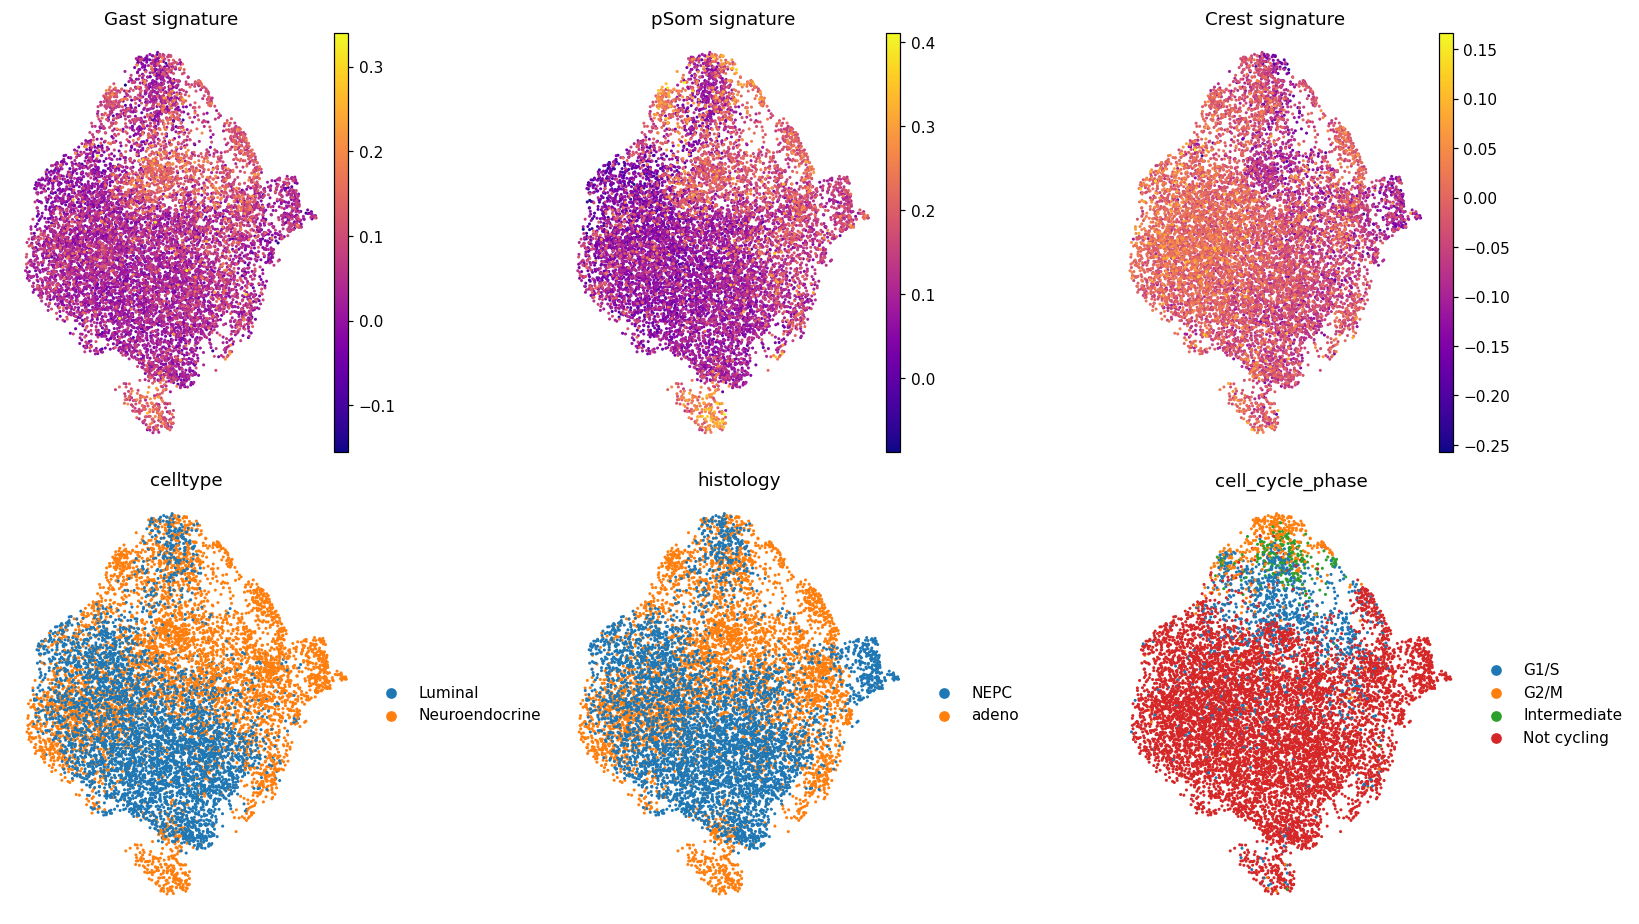

In [16]:
# biology overview figure: modules + subtype + cycle on the integrated manifold
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for i, col in enumerate(['Gast','pSom','Crest']):
    sc.pl.umap(adata, color=col, cmap='plasma', size=16, ax=axes[0,i], show=False, frameon=False, title=col+' signature')
for i, col in enumerate(['celltype','histology','cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=16, ax=axes[1,i], show=False, frameon=False, title=col, legend_loc='right margin')
plt.tight_layout(); plt.show()

**Region biology.** The manifold carries a **shared Gast/pSom gradient** (both high in the upper-right,
strongly co-varying, r ≈ +0.9) with **Crest as an inverse gradient** — the reference non-branching
relationship. The neuroendocrine (ASCL1/CHGA/SYP-high) and luminal (AR/NKX3-1/FOLH1-high) states are the two
poles of the *same* continuous manifold, and the Gast/pSom↔Crest relationship holds within **each** state and
in **non-cycling** cells, so it is neither a lineage artifact nor a proliferation artifact. Cycling cells are
a scattered minority (~18%), not a detached second lineage. The whole malignant compartment is kept as the
trajectory object.

In [17]:
# house linear orientation (X_umap_lin): rigid rotation to the principal axis, origin pole to the left.
# Distances are preserved (no re-embedding of the strip); reused verbatim by 02/03/04.
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],[np.sin(-theta_rot), np.cos(-theta_rot)]])
xyr = c @ Rm.T
# developmental origin = Gast/pSom-high, Crest-low -> place on the left (negative x)
origin = (adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values) - adata.obs['Crest_sm'].values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
adata.uns['lin_rot'] = float(theta_rot)
adata.uns['lin_mean'] = xy.mean(0)
print(f'manifold aspect (max/min std): {aspect:.2f}  |  house orientation rotation {np.degrees(theta_rot):+.1f} deg')

manifold aspect (max/min std): 1.09  |  house orientation rotation -170.4 deg


In [18]:
adata.uns['gate1'] = 'GO'
adata.uns['gate1_reason'] = 'samples intermix (iLISI 1.93/4 at theta=10) on ONE connected continuous manifold; no islands'
adata.uns['sweep_ilisi'] = {str(k): float(v) for k,v in sweep.items()}
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9698, 15672)


saved samples.pdf | cells: 9698


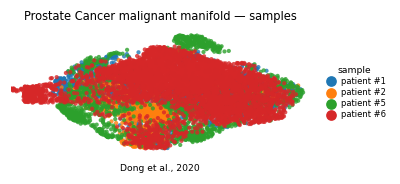

In [19]:
# samples.pdf — single sample-colored manifold UMAP, house (3.5,1.5) strip on X_umap_lin (reference style)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate Cancer malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])

## Gate 1 verdict — **GO**

The malignant compartment is **sample-integrated and continuous**:

- At the strongest non-collapsing integration (**theta = 10**) the four samples intermix per-neighbourhood
  (**mean iLISI 1.93 of 4**, up monotonically from 1.0 pre-Harmony), and the embedding is **one connected
  component** on both the kNN graph and an independent UMAP radius graph — no detached islands.
- The luminal-adenocarcinoma and neuroendocrine states are two poles of a **single continuous manifold**, and
  the reference embryonic relationship (Gast/pSom co-vary, both oppose Crest) holds within each state and in
  non-cycling cells — so the whole manifold is the trajectory region.

We proceed to **02_manifold** to fit the cell-state trajectory.